In [ ]:
# Problem Set 2: ML Use Case
# Number of Fraudulent Transactions Flagged


# Given values
n = 50                 # Transactions examined per hour
p = 0.04               # Probability of being flagged
num_hours = 20000      # Number of one-hour periods

# Investigation team capacity
capacity = 4


In [ ]:

# Step 1: Define the Random Variable
# X = Number of transactions flagged in one hour
#
# X follows a Binomial distribution:
#
# X ~ Binomial(n=50, p=0.04)

print("Random Variable:")
print("X = Number of transactions flagged in one hour")
print("Distribution = Binomial")
print("n =", n)
print("p =", p)
print("Number of simulated hours =", num_hours)
print("Investigation capacity =", capacity)


Random Variable:
X = Number of transactions flagged in one hour
Distribution = Binomial
n = 50
p = 0.04
Number of simulated hours = 20000
Investigation capacity = 4


In [ ]:
# Step 2: Simulate 20,000 One-Hour Periods


flagged_transactions = np.random.binomial(
    n=n,
    p=p,
    size=num_hours
)


In [ ]:
# Step 3: Display Simulated Results


print("\nFirst 20 simulated one-hour periods:")

simulation_table = pd.DataFrame({
    "Hour": np.arange(1, 21),
    "Flagged Transactions": flagged_transactions[:20]
})

simulation_table


First 20 simulated one-hour periods:


,Hour,Flagged Transactions
0,1,4
1,2,1
2,3,1
3,4,2
4,5,2
5,6,6
6,7,2
7,8,1
8,9,2
9,10,0


In [ ]:
# Step 4: Simulation Summary


print("Total simulated one-hour periods:", len(flagged_transactions))

print(
    "Total transactions examined:",
    num_hours * n
)

print(
    "Average flagged transactions per hour:",
    np.mean(flagged_transactions)
)

print(
    "Minimum flagged transactions in an hour:",
    np.min(flagged_transactions)
)

print(
    "Maximum flagged transactions in an hour:",
    np.max(flagged_transactions)
)

Total simulated one-hour periods: 20000
Total transactions examined: 1000000
Average flagged transactions per hour: 2.0103
Minimum flagged transactions in an hour: 0
Maximum flagged transactions in an hour: 10


In [ ]:
# Step 5: Investigation Capacity


hours_within_capacity = np.sum(
    flagged_transactions <= capacity
)

hours_exceeding_capacity = np.sum(
    flagged_transactions > capacity
)

print("Hours within investigation capacity:",
      hours_within_capacity)

print("Hours exceeding investigation capacity:",
      hours_exceeding_capacity)

probability_exceeding_capacity = (
    hours_exceeding_capacity / num_hours
)

print(
    "Empirical probability of exceeding capacity:",
    probability_exceeding_capacity
)

Hours within investigation capacity: 19009
Hours exceeding investigation capacity: 991
Empirical probability of exceeding capacity: 0.04955


In [ ]:
# Step 6: Summary Table


summary_table = pd.DataFrame({
    "Measure": [
        "Number of simulated hours",
        "Transactions per hour",
        "Flagging probability",
        "Investigation capacity",
        "Average flagged transactions per hour",
        "Minimum flagged transactions",
        "Maximum flagged transactions",
        "Hours within capacity",
        "Hours exceeding capacity",
        "Probability of exceeding capacity"
    ],

    "Value": [
        num_hours,
        n,
        p,
        capacity,
        np.mean(flagged_transactions),
        np.min(flagged_transactions),
        np.max(flagged_transactions),
        hours_within_capacity,
        hours_exceeding_capacity,
        probability_exceeding_capacity
    ]
})

summary_table

,Measure,Value
0,Number of simulated hours,20000.00000
1,Transactions per hour,50.00000
2,Flagging probability,0.04000
3,Investigation capacity,4.00000
4,Average flagged transactions per hour,2.01030
5,Minimum flagged transactions,0.00000
6,Maximum flagged transactions,10.00000
7,Hours within capacity,19009.00000
8,Hours exceeding capacity,991.00000
9,Probability of exceeding capacity,0.04955


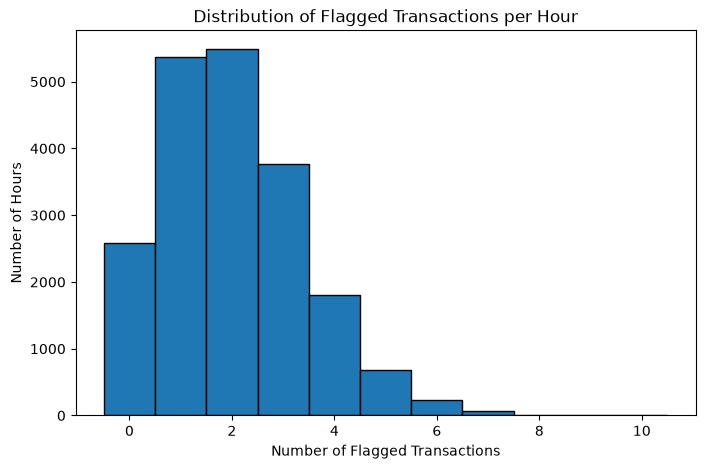

In [ ]:
# Step 7: Distribution of Flagged Transactions


plt.figure(figsize=(8, 5))

plt.hist(
    flagged_transactions,
    bins=np.arange(
        flagged_transactions.min(),
        flagged_transactions.max() + 2
    ) - 0.5,
    edgecolor="black"
)

plt.xlabel("Number of Flagged Transactions")
plt.ylabel("Number of Hours")
plt.title(
    "Distribution of Flagged Transactions per Hour"
)

plt.show()